# Task 1.1 – Word2Vec (skip-gram) on TASA, evaluated on TOEFL
Christos Palantzidis · D7041E Lab 2

Run the cells from top to bottom. 3 dimensions × 5 seeds = 15 models (≈ 30–50 min on Colab).

In [1]:
# Install Gensim (Word2Vec), NLTK (lemmatizer), pandas (tables) and matplotlib (plots).
%pip install -q gensim nltk pandas matplotlib

In [2]:
# Import the Colab helper that connects this notebook to Google Drive.
from google.colab import drive
# Import Path to build file and folder paths.
from pathlib import Path
# Import ZipFile to read files directly from NLP.zip.
from zipfile import ZipFile

# Connect Google Drive; Colab asks for permission the first time.
drive.mount("/content/drive")
# The Drive folder that contains NLP.zip.
drive_folder = Path("/content/drive/MyDrive/Lab2 advanced AI")
# Full path of the ZIP file inside that folder.
zip_path = drive_folder / "NLP.zip"
# Stop with a clear message if the ZIP file is not where we expect it.
if not zip_path.is_file():
    # Show the exact path that was checked.
    raise FileNotFoundError(f"Could not find the ZIP file at {zip_path}")

# Folder on Colab's fast local disk where the files are extracted.
local_folder = Path("/content/lab2")
# Open the ZIP file (it is closed automatically at the end of the block).
with ZipFile(zip_path) as archive:
    # Extract the lemmatized TASA corpus used for training.
    training_file = Path(archive.extract("Part2_NLP/GensimW2V/lemmatized.text", path=local_folder))
    # Extract the 80 TOEFL synonym questions used for testing.
    toefl_file = Path(archive.extract("Part2_NLP/GensimW2V/new_toefl.txt", path=local_folder))

# Open the corpus to check that it can be read.
with training_file.open(encoding="utf-8") as f:
    # Print the first line as an example of the (lemmatized) text.
    print("TASA example:", f.readline().strip())

Mounted at /content/drive
TASA example: who be the first american


In [3]:
# Import NLTK, which provides the WordNet lemmatizer.
import nltk
# Import NumPy for vectors, random numbers and dot products.
import numpy as np
# Import the lemmatizer class.
from nltk.stem import WordNetLemmatizer

# Download the WordNet dictionary needed by the lemmatizer (quietly).
nltk.download("wordnet", quiet=True)
# Create one lemmatizer object and reuse it for all words.
lemmatizer = WordNetLemmatizer()


# Define a function that turns a word into its base form (lemma).
def normalize_word(word):
    # Try the word as a verb, then as a noun, then as an adjective (as in the course code).
    for pos in ("v", "n", "a"):
        # Each step starts from the result of the previous step.
        word = lemmatizer.lemmatize(word, pos=pos)
    # Return the final base form, e.g. "showed" -> "show".
    return word


# Open the TOEFL file; each line = query word, correct synonym, 3 wrong alternatives.
with toefl_file.open(encoding="utf-8") as f:
    # Lemmatize the 5 words of every non-empty line and keep them as one question.
    questions = [[normalize_word(w) for w in line.split()] for line in f if line.strip()]
# Confirm that all 80 questions were loaded.
print("TOEFL questions loaded:", len(questions))


# Define the cosine similarity between two vectors.
def cosine(x, y):
    # Dot product divided by the product of the two vector lengths.
    return float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y)))


# Define the TOEFL test with the same rules as the course code (GensimW2V/main.py).
def evaluate_toefl(model, questions, seed):
    # Random generator for vectors of alternatives that are missing from the vocabulary.
    rng = np.random.default_rng(seed)
    # Start counting correct answers and skipped questions from zero.
    correct, skipped = 0, 0
    # Split every question into the query word and its 4 alternatives.
    for query, *options in questions:
        # If the query word never occurs in TASA it has no vector...
        if query not in model.wv:
            # ...so we skip the question (it still counts as wrong).
            skipped += 1
            # Go to the next question.
            continue
        # Get the learned vector of the query word.
        q = model.wv[query]
        # Learned vector for each alternative; a random vector if the alternative is missing.
        vectors = [model.wv[o] if o in model.wv else rng.standard_normal(model.vector_size)
                   for o in options]
        # Cosine similarity between the query and each of the 4 alternatives.
        scores = [cosine(q, v) for v in vectors]
        # The first alternative is always the correct synonym in new_toefl.txt.
        if int(np.argmax(scores)) == 0:
            # The model chose the correct synonym.
            correct += 1
    # Return the number of correct answers and of skipped questions.
    return correct, skipped

TOEFL questions loaded: 80


In [4]:
# Import a precise timer to measure training time.
from time import perf_counter
# Import pandas to show the results as a table.
import pandas as pd
# Import the Word2Vec model from Gensim.
from gensim.models import Word2Vec

# Open the corpus once.
with training_file.open(encoding="utf-8") as f:
    # Store every line as a list of words (Word2Vec's input format).
    sentences = [line.split() for line in f]
# Show the size of the corpus.
print(f"{len(sentences):,} lines, {sum(map(len, sentences)):,} tokens")

# The three vector sizes (numbers per word) we compare.
dimensions = (10, 100, 300)
# Five different random seeds = five independent runs per dimension.
seeds = (17, 23, 31, 47, 59)
# Empty list that will collect one result per run.
results = []

# Loop over the three dimensions.
for dimension in dimensions:
    # Loop over the five seeds.
    for seed in seeds:
        # Start the timer just before training.
        start = perf_counter()
        # Create and train a new Word2Vec model on the whole corpus.
        model = Word2Vec(
            sentences,               # training data: list of tokenized lines
            vector_size=dimension,   # numbers per word vector
            sg=1,                    # skip-gram: predict neighbours from the centre word
            min_count=1,             # keep every word, even if it occurs once
            sample=0.00055,          # down-sample very frequent words
            window=5,                # up to 5 neighbours on each side
            negative=5,              # 5 random "negative" words per training pair
            epochs=5,                # 5 passes over the corpus
            workers=2,               # use the 2 CPU cores of Colab
            seed=seed,               # seed for the random initialisation
        )
        # Stop the timer: seconds needed to train this model.
        train_s = perf_counter() - start
        # Run the TOEFL test on the trained model.
        correct, skipped = evaluate_toefl(model, questions, seed)
        # Accuracy in percent, always divided by all 80 questions.
        acc = 100 * correct / len(questions)
        # Store the settings and results of this run.
        results.append({"dimension": dimension, "seed": seed, "correct_out_of_80": correct,
                        "skipped": skipped, "accuracy_pct": acc, "training_seconds": train_s})
        # Print the result immediately, so we can follow the progress.
        print(f"d={dimension:4d} seed={seed} correct={correct}/80 accuracy={acc:.2f}% "
              f"skipped={skipped} time={train_s:.0f}s", flush=True)

# Turn the list of results into a table.
results_df = pd.DataFrame(results)
# Show all 15 runs, rounded to 2 decimals.
display(results_df.round(2))

752,149 lines, 10,766,283 tokens
d=  10 seed=17 correct=41/80 accuracy=51.25% skipped=1 time=179s
d=  10 seed=23 correct=38/80 accuracy=47.50% skipped=1 time=179s
d=  10 seed=31 correct=43/80 accuracy=53.75% skipped=1 time=179s
d=  10 seed=47 correct=36/80 accuracy=45.00% skipped=1 time=180s
d=  10 seed=59 correct=41/80 accuracy=51.25% skipped=1 time=177s
d= 100 seed=17 correct=53/80 accuracy=66.25% skipped=1 time=234s
d= 100 seed=23 correct=57/80 accuracy=71.25% skipped=1 time=233s
d= 100 seed=31 correct=57/80 accuracy=71.25% skipped=1 time=229s
d= 100 seed=47 correct=59/80 accuracy=73.75% skipped=1 time=233s
d= 100 seed=59 correct=55/80 accuracy=68.75% skipped=1 time=231s
d= 300 seed=17 correct=58/80 accuracy=72.50% skipped=1 time=349s
d= 300 seed=23 correct=55/80 accuracy=68.75% skipped=1 time=353s
d= 300 seed=31 correct=59/80 accuracy=73.75% skipped=1 time=352s
d= 300 seed=47 correct=60/80 accuracy=75.00% skipped=1 time=355s
d= 300 seed=59 correct=61/80 accuracy=76.25% skipped=1 ti

,dimension,seed,correct_out_of_80,skipped,accuracy_pct,training_seconds
0,10,17,41,1,51.25,178.88
1,10,23,38,1,47.50,179.48
2,10,31,43,1,53.75,179.22
3,10,47,36,1,45.00,180.36
4,10,59,41,1,51.25,177.46
5,100,17,53,1,66.25,234.47
6,100,23,57,1,71.25,233.18
7,100,31,57,1,71.25,229.24
8,100,47,59,1,73.75,233.08
9,100,59,55,1,68.75,231.44


,dimension,runs,mean_accuracy_pct,sd_accuracy_pct,mean_training_sec
0,10,5,49.75,3.47,179.08
1,100,5,70.25,2.85,232.28
2,300,5,73.25,2.88,352.49


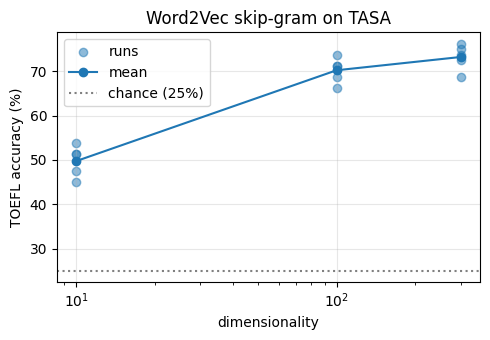

Saved to: /content/drive/MyDrive/Lab2 advanced AI


In [5]:
# Import matplotlib to draw the accuracy plot.
import matplotlib.pyplot as plt

# Group the 15 runs by dimension and compute summary statistics.
summary_df = results_df.groupby("dimension", as_index=False).agg(
    runs=("seed", "count"),                          # number of runs per dimension
    mean_accuracy_pct=("accuracy_pct", "mean"),      # average accuracy
    sd_accuracy_pct=("accuracy_pct", "std"),         # spread between runs
    mean_training_sec=("training_seconds", "mean"),  # average training time
)
# Show the summary table (3 rows, one per dimension).
display(summary_df.round(2))

# Create a small figure.
plt.figure(figsize=(5, 3.5))
# One dot per run.
plt.scatter(results_df["dimension"], results_df["accuracy_pct"], alpha=.5, label="runs")
# Line through the mean accuracy of each dimension.
plt.plot(summary_df["dimension"], summary_df["mean_accuracy_pct"], "o-", label="mean")
# Dotted line at 25 %, the accuracy of random guessing.
plt.axhline(25, ls=":", color="grey", label="chance (25%)")
# Logarithmic x-axis because the dimensions grow by factors of 10 and 3.
plt.xscale("log")
# Label of the x-axis.
plt.xlabel("dimensionality")
# Label of the y-axis.
plt.ylabel("TOEFL accuracy (%)")
# Title of the plot.
plt.title("Word2Vec skip-gram on TASA")
# Show the legend.
plt.legend()
# Light grid lines for easier reading.
plt.grid(alpha=.3)
# Avoid overlapping labels.
plt.tight_layout()
# Save the plot as a PNG file in the Drive folder.
plt.savefig(drive_folder / "task1_1_word2vec.png", dpi=150)
# Display the plot in the notebook.
plt.show()

# Save all 15 runs as a CSV file in the Drive folder.
results_df.to_csv(drive_folder / "task1_1_word2vec_results.csv", index=False)
# Confirm where the files were saved.
print("Saved to:", drive_folder)